In [2]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ks_2samp, ttest_ind, mannwhitneyu, levene
import tensorflow as tf

def encontrar_raiz_repo(marcadores=(".git", "data")):
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if all((pasta / m).exists() for m in marcadores):
            return pasta
    raise FileNotFoundError(f"Nao achei {marcadores} subindo a partir de {Path.cwd()}")


RAIZ = encontrar_raiz_repo()
pd.set_option("display.width", 200)

In [3]:
# Regressão
from notebooks.src.regression import Regression

## Importando dados

In [4]:
clusters = pd.read_csv(RAIZ / "data/processed/clusters_risco.csv", index_col=0)
metadata = pd.read_csv(RAIZ / "data/raw/metadata_recorte.csv", index_col=0)
df = clusters.join(metadata.drop(columns=["Species"]), how="left")

print(df.shape)
df.head()

(2226, 12)


,cluster,conjunto,perfil,Species,Source,Date,Location,BioSample,Estado,Região,source_type,WHO_Priority
sample,,,,,,,,,,,,
GCA_029076165.1,2,treino,C2: carbapenemase serina (plasm. 61%),Klebsiella pneumoniae,urine,2021.0,Brazil,SAMN33566985,NaN,NaN,Urinary,Critical
GCF_001420335.1,2,treino,C2: carbapenemase serina (plasm. 61%),Acinetobacter baumannii,rectal swab,2012.0,"Hospital das Clinicas, Sao Paulo",SAMN04196794,SP,Sul,Gastrointestinal,Critical
GCA_002304205.1,1,treino,C1: ESBL sem carbapenemase,Klebsiella pneumoniae,rectal swab,2011.0,Brazil,SAMN07595147,NaN,NaN,Gastrointestinal,Critical
GCA_031011085.1,3,treino,C3: carbapenemase serina + ESBL (plasm. 96%),Klebsiella pneumoniae,Surveillance Swab,2019.0,Brazil,SAMN36785147,NaN,NaN,Other,Critical
GCA_031630615.1,0,treino,C0: MBL + ESBL (plasm. 80%),Enterobacter hormaechei,blood,2020.0,Sao Paulo,SAMN30951027,SP,Sul,Blood,Critical


### Criando as colunas X

In [5]:
CONTEXTO = ["Species", "source_type", "Date"]

df_contexto = df[CONTEXTO]
df_contexto.head()

,Species,source_type,Date
sample,,,
GCA_029076165.1,Klebsiella pneumoniae,Urinary,2021.0
GCF_001420335.1,Acinetobacter baumannii,Gastrointestinal,2012.0
GCA_002304205.1,Klebsiella pneumoniae,Gastrointestinal,2011.0
GCA_031011085.1,Klebsiella pneumoniae,Other,2019.0
GCA_031630615.1,Enterobacter hormaechei,Blood,2020.0


### Importando as features usadas na classificação e clusterização

In [6]:
df_train = pd.read_csv("data/processed/df_estruturada/df_train_risco.csv", index_col=0)
df_valid  = pd.read_csv("data/processed/df_estruturada/df_valid_risco.csv",  index_col=0)
df_test  = pd.read_csv("data/processed/df_estruturada/df_test_risco.csv",  index_col=0)

In [7]:
df_train.drop(columns=["Species"], axis=1, inplace=True)
df_valid.drop(columns=["Species"], axis=1, inplace=True)
df_test.drop(columns=["Species"], axis=1, inplace=True)

In [8]:
print(len(df_train))
print(len(df_valid))
print(len(df_test))

1558
445
223


### Calculando valor contínuo de risco
- `n de bl adquiridas` x `peso do tipo de bl` x `fração plasmidial`

In [9]:
def risco_idx(df, w_plasmid=0.5):
    carb = df["has_carbapenemase"] > 0
    esbl = df["has_esbl"] > 0
    ampc = df["has_ampc_adquirida"] > 0
    tipo = np.select(
        [carb & (esbl | ampc),   
         carb,                   
         esbl,                   
         ampc],                  
        [1.0, 0.75, 0.5, 0.25], default=0.0)
    pct_adquiridos_plasmidial = df["pct_adquiridos_plasmidial"].fillna(0)
    return df["n_bl_adquiridas"] * tipo * (1 + w_plasmid * pct_adquiridos_plasmidial)

risco_idx(df_train).head()

sample
GCA_029076165.1    2.025000
GCF_001420335.1    2.000000
GCA_002304205.1    0.659091
GCA_031011085.1    5.529412
GCA_031630615.1    3.714286
dtype: float64

In [10]:
median_treino_date = df_contexto.loc[df_train.index, "Date"].median()
contagem_species = df_contexto.loc[df_train.index, "Species"].value_counts()
raras = contagem_species[contagem_species < 10].index     

raras

Index(['Klebsiella variicola', 'Providencia stuartii', 'Citrobacter freundii', 'Yersinia enterocolitica', 'Enterobacter roggenkampii', 'Enterobacter cloacae', 'Klebsiella michiganensis',
       'Klebsiella sp.', 'Enterobacter asburiae', 'Providencia rettgeri', 'Morganella morganii', 'Citrobacter portucalensis', 'Klebsiella oxytoca', 'Raoultella ornithinolytica', 'Proteus vulgaris',
       'Citrobacter koseri', 'Pseudocitrobacter sp.', 'Raoultella planticola', 'Enterobacter bugandensis', 'Kluyvera ascorbata', 'Pluralibacter gergoviae', 'Escherichia sp.', 'Serratia nevei',
       'Enterobacter kobei', 'Escherichia albertii'],
      dtype='object')

In [11]:
def features(df_risco, df_contexto, med_date, raras):
    d = df_risco.join(df_contexto, how="inner")        # índice = sample
    out = d[CONTEXTO].copy()
    out["risco_idx"] = risco_idx(d)                    
    out["Date_na"] = out["Date"].isna().astype(int)
    out["Date"] = out["Date"].fillna(med_date)
    out["Species"] = out["Species"].where(~out["Species"].isin(raras), "Outras")
    return out

In [12]:
tr = features(df_train, df_contexto, median_treino_date, raras)
va = features(df_valid, df_contexto, median_treino_date, raras)
te = features(df_test,  df_contexto, median_treino_date, raras)

In [13]:
tr

,Species,source_type,Date,risco_idx,Date_na
sample,,,,,
GCA_029076165.1,Klebsiella pneumoniae,Urinary,2021.0,2.025000,0
GCF_001420335.1,Acinetobacter baumannii,Gastrointestinal,2012.0,2.000000,0
GCA_002304205.1,Klebsiella pneumoniae,Gastrointestinal,2011.0,0.659091,0
GCA_031011085.1,Klebsiella pneumoniae,Other,2019.0,5.529412,0
GCA_031630615.1,Enterobacter hormaechei,Blood,2020.0,3.714286,0
...,...,...,...,...,...
GCA_022209385.1,Klebsiella pneumoniae,Unknown,2018.0,7.187500,0
GCA_026191975.1,Klebsiella pneumoniae,Urinary,2017.0,4.071429,0
GCA_003651285.1,Escherichia coli,Gastrointestinal,1989.0,0.000000,0


### 'ydata' manual

In [14]:
FEATURES = ["Species", "source_type", "Date"]
Y = "risco_idx"
NUM = [c for c in FEATURES if pd.api.types.is_numeric_dtype(tr[c])]
CAT = [c for c in FEATURES if c not in NUM]
cols = FEATURES + [Y]

perfil = pd.DataFrame({
    "tipo": tr[cols].dtypes.astype(str),
    "nulos %": (tr[cols].isna().mean() * 100).round(1),
    "únicos": tr[cols].nunique(),
    "top (freq %)": [f"{tr[c].value_counts().index[0]} ({tr[c].value_counts(normalize=True).iloc[0]*100:.0f}%)" for c in cols],
})
perfil

,tipo,nulos %,únicos,top (freq %)
Species,object,0.0,9,Klebsiella pneumoniae (47%)
source_type,object,0.0,10,Blood (28%)
Date,float64,0.0,34,2016.0 (14%)
risco_idx,float64,0.0,330,0.0 (20%)


## Cross Validation e Hiperparametros

In [15]:
print('df treino:')
display(tr.head())
print('Len treino', len(tr))
print('Len valid', len(va))
print('Len teste', len(te))

df treino:


,Species,source_type,Date,risco_idx,Date_na
sample,,,,,
GCA_029076165.1,Klebsiella pneumoniae,Urinary,2021.0,2.025000,0
GCF_001420335.1,Acinetobacter baumannii,Gastrointestinal,2012.0,2.000000,0
GCA_002304205.1,Klebsiella pneumoniae,Gastrointestinal,2011.0,0.659091,0
GCA_031011085.1,Klebsiella pneumoniae,Other,2019.0,5.529412,0
GCA_031630615.1,Enterobacter hormaechei,Blood,2020.0,3.714286,0


Len treino 1558
Len valid 445
Len teste 223


In [16]:
regressor = Regression(df=tr, target="risco_idx")

In [17]:
print('regressor.X.columns:', regressor.X.columns)

print('regressor.y.shape:' , regressor.y.shape)

regressor.X.columns: Index(['Species', 'source_type', 'Date', 'Date_na'], dtype='object')
regressor.y.shape: (1558,)


1. Padroniza as numéricas (Date, Date_na) e faz one-hot das categóricas.
2. Descarta colunas quase constantes (VarianceThreshold).
3. Escolhe as k melhores pelo f_regression.
4. Ajusta a regressão linear, testando o Grid Search com Cross validation de 5 folds.
5. Imprime os melhores parâmetros, quantas variáveis sobraram e quais foram, e o gráfico predito × observado.

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown

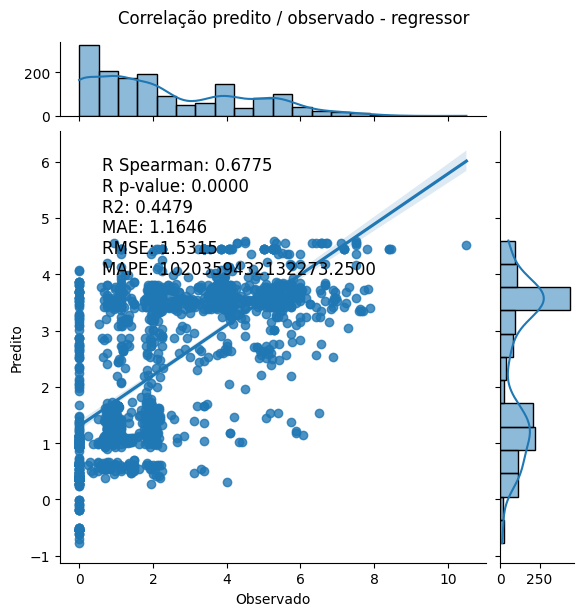

In [18]:
metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 1
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown
19. cat__s

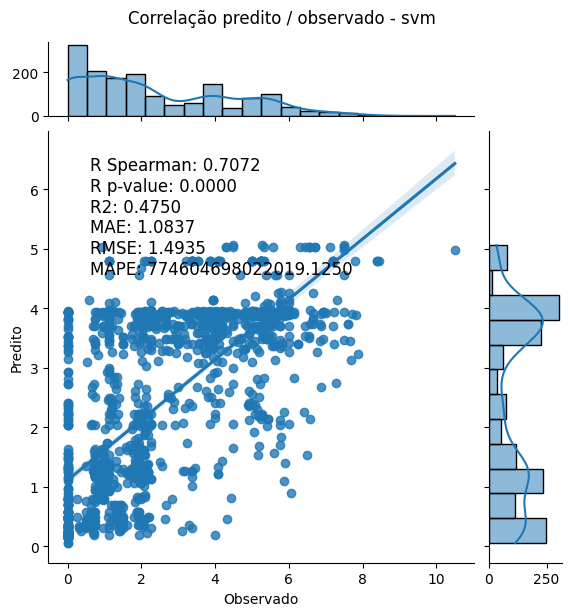

In [19]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

In [20]:
!grep -n "sparse_output" /usr/src/myapp/notebooks/src/regression.py

181:                    OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),  # <- ALTERADO


In [21]:
regressor = Regression(df=tr, target="risco_idx")

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unkno

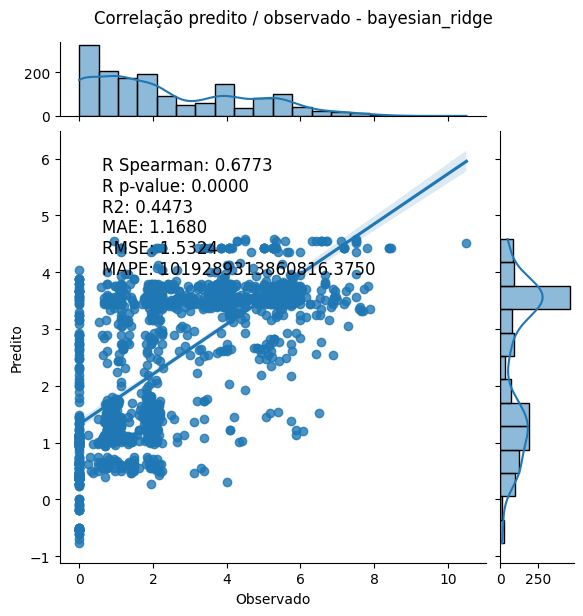

In [22]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.ap

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.05
nn__optimizer -> RMSprop
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> sigmoid
nn__activation1 -> tanh
feature_selection__k -> all
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    9
Total de variáveis selecionadas no modelo:    9

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Escherichia coli
4. cat__Species_Klebsiella pneumoniae
5. cat__source_type_Gastrointestinal
6. cat__source_type_Other
7. cat__source_type_Respiratory
8. cat__source_type_Unknown
9. cat__source_type_Urinary

--- Status de Cada Atributo no Pipeline ---
                 Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                              num__Date              True               True
                           num__Date_na              True               Tr

/usr/local/lib/python3.10/site-packages/sklearn/pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


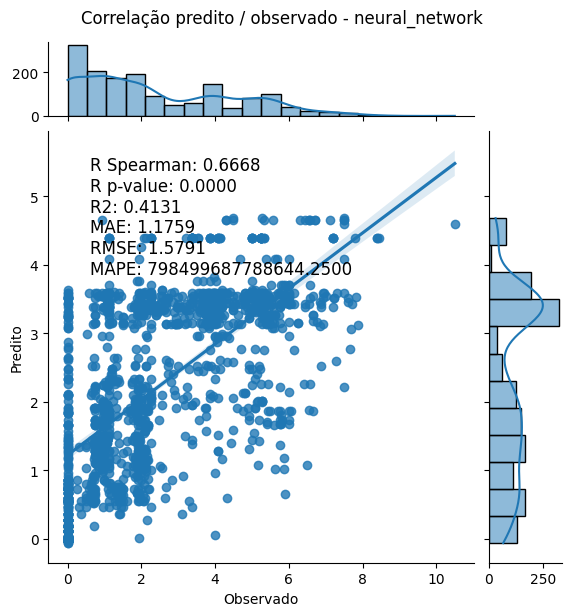

In [23]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [24]:
algoritmo_1 = "Multiple Linear Regression"
algoritmo_2 = "Suport Vector Machine"
algoritmo_3 = "Nayve Bayes"
algoritmo_4 = "Neural Network"

# Organizando as métricas de treinamento
df_metricas_train = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_train.reset_index(inplace=True)
df_metricas_train["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_train.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_train.head()

,metricas,valores,modelo
0,R Spearman,0.6775,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.4479,Multiple Linear Regression
3,MAE,1.1646,Multiple Linear Regression
4,RMSE,1.5315,Multiple Linear Regression


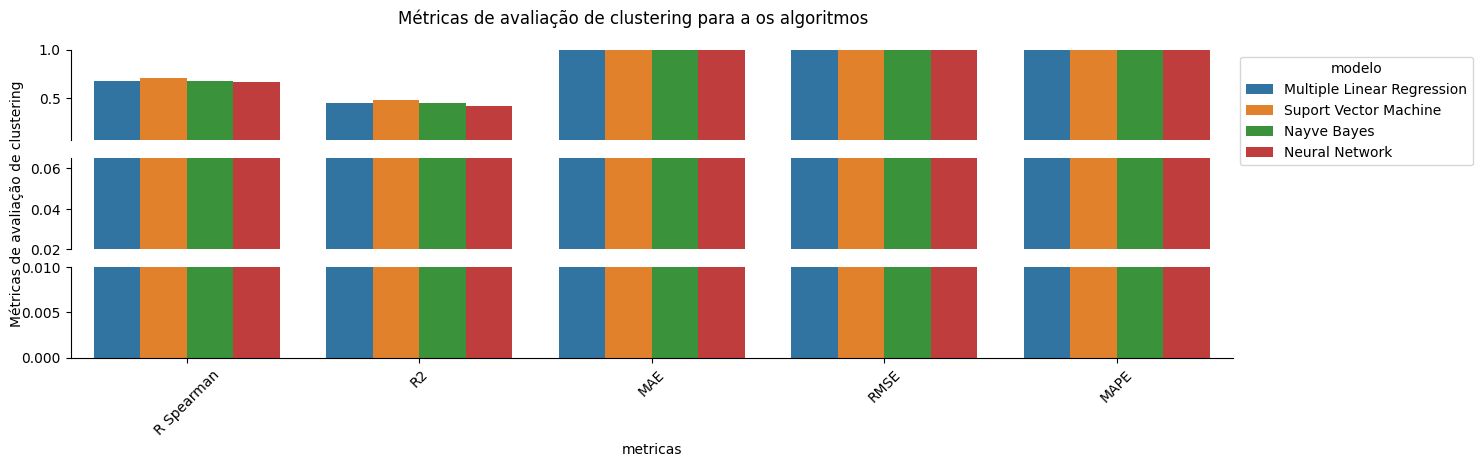

In [25]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.065, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.065)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [26]:
tr[algoritmo_1] = pred_regr.copy()
tr[algoritmo_2] = pred_svm.copy()
tr[algoritmo_3] = pred_nb.copy()
tr[algoritmo_4] = pred_nn.copy()

tr.head()

,Species,source_type,Date,risco_idx,Date_na,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
sample,,,,,,,,,
GCA_029076165.1,Klebsiella pneumoniae,Urinary,2021.0,2.025000,0,3.426626,3.709819,3.434216,3.389543
GCF_001420335.1,Acinetobacter baumannii,Gastrointestinal,2012.0,2.000000,0,0.459236,1.246998,0.551359,0.963116
GCA_002304205.1,Klebsiella pneumoniae,Gastrointestinal,2011.0,0.659091,0,2.524577,2.685992,2.537948,2.529052
GCA_031011085.1,Klebsiella pneumoniae,Other,2019.0,5.529412,0,3.666590,3.977179,3.680924,3.711617
GCA_031630615.1,Enterobacter hormaechei,Blood,2020.0,3.714286,0,3.945243,3.246767,3.752767,1.912508


## Validação

In [27]:
va.head()

,Species,source_type,Date,risco_idx,Date_na
sample,,,,,
GCA_002209465.1,Klebsiella pneumoniae,CNS,2015.0,0.500000,0
GCA_007648605.1,Escherichia coli,Gastrointestinal,2015.0,0.000000,0
GCA_051169655.1,Acinetobacter baumannii,Other,2021.0,0.968750,0
GCA_016990875.1,Escherichia coli,Urinary,2016.0,1.400000,0
GCA_016991135.1,Escherichia coli,Urinary,2016.0,2.714286,0


Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.01
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    16
Total de variáveis selecionadas no modelo:    16

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. cat__Species_Enterobacter hormaechei
3. cat__Species_Escherichia coli
4. cat__Species_Klebsiella aerogenes
5. cat__Species_Klebsiella pneumoniae
6. cat__Species_Klebsiella quasipneumoniae
7. cat__Species_Outras
8. cat__Species_Serratia marcescens
9. cat__source_type_CNS
10. cat__source_type_Gastrointestinal
11. cat__source_type_Medical Device
12. cat__source_type_Other
13. cat__source_type_Respiratory
14. cat__source_type_Skin & Soft Tissue
15. cat__source_type_Unknown
16. cat__source_type_Urinary

--- Status de Cada Atributo no Pipeline ---
           

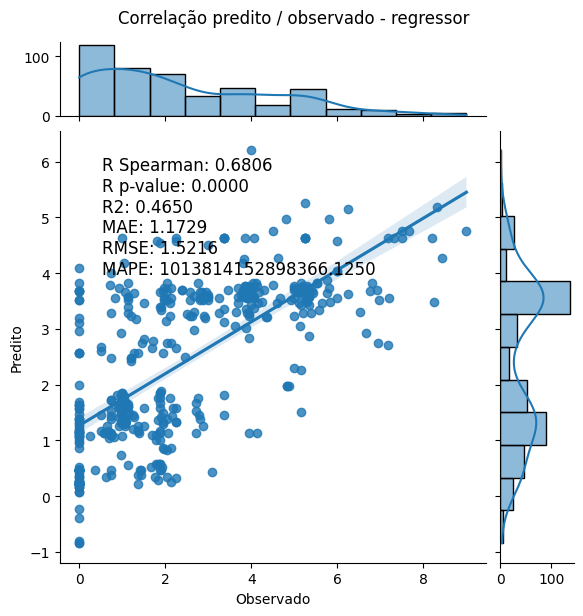

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    18
Total de variáveis selecionadas no modelo:    18

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. cat__Species_Enterobacter chengduensis
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_CNS
12. cat__source_type_Gastrointestinal
13. cat__source_type_Medical Device
14. cat__source_type_Other
15. cat__source_type_Respiratory
16. cat__source_type_Skin & Soft Tissue
17. cat__source_type_Unknown
18. cat__source

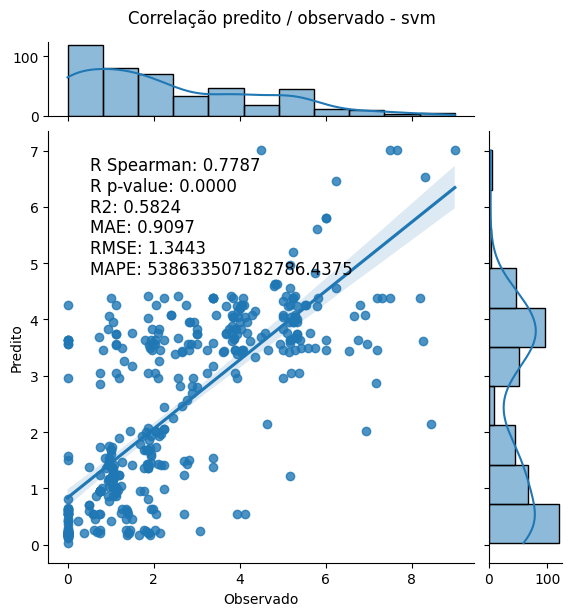

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    18
Total de variáveis selecionadas no modelo:    18

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. cat__Species_Enterobacter chengduensis
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_CNS
12. cat__source_type_Gastrointestinal
13. cat__source_type_Medical Device
14. cat__source_type_Other
15. cat__source_type_Respiratory
16. cat__source_type_Skin & Soft Tissue
17. cat__source_type_Unknown
18.

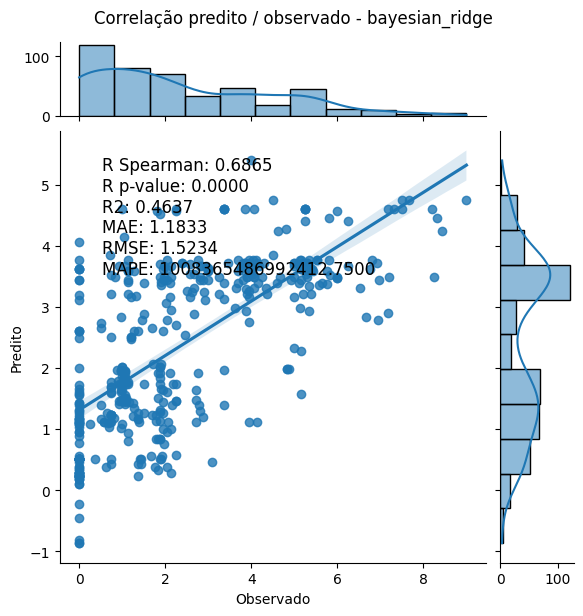

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.ap

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 10
nn__batch_size -> 32
nn__activation2 -> tanh
nn__activation1 -> relu
feature_selection__k -> all
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    16
Total de variáveis selecionadas no modelo:    16

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. cat__Species_Enterobacter hormaechei
3. cat__Species_Escherichia coli
4. cat__Species_Klebsiella aerogenes
5. cat__Species_Klebsiella pneumoniae
6. cat__Species_Klebsiella quasipneumoniae
7. cat__Species_Outras
8. cat__Species_Serratia marcescens
9. cat__source_type_CNS
10. cat__source_type_Gastrointestinal
11. cat__source_type_Medical Device
12. cat__source_type_Other
13. cat__source_type_Respiratory
14. cat__source_type_Skin & Soft Tissue
15. cat__source_type_Unknown
16. cat__source_type_Urinary

--- Status

/usr/local/lib/python3.10/site-packages/sklearn/pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


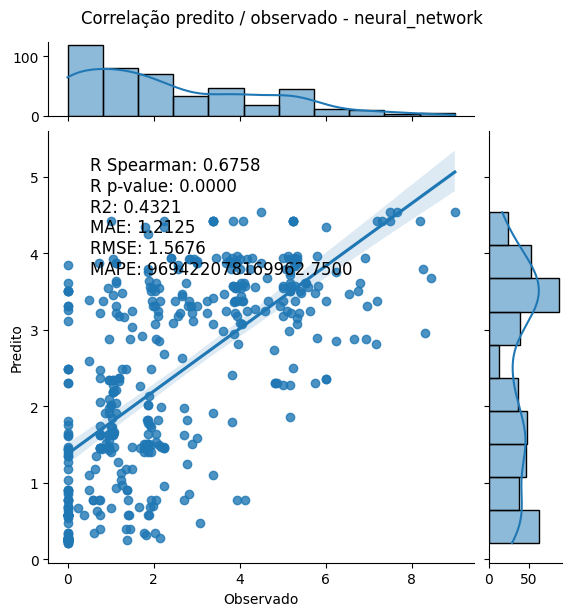

In [28]:
regressor = Regression(df=va, target="risco_idx")

metricas_regr, pred_regr = regressor.regress(modelo="regressor")
metricas_svm,  pred_svm  = regressor.regress(modelo="svm")
metricas_nb,   pred_nb   = regressor.regress(modelo="bayesian_ridge")
metricas_nn,   pred_nn   = regressor.regress(modelo="neural_network", n_iter_search=5)

In [29]:
df_metricas_valid = pd.concat([metricas_regr.T.copy(), metricas_svm.T.copy(),
                               metricas_nb.T.copy(), metricas_nn.T.copy()])
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = ([algoritmo_1]*6 + [algoritmo_2]*6 + [algoritmo_3]*6 + [algoritmo_4]*6)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)

va[algoritmo_1] = pred_regr.copy()
va[algoritmo_2] = pred_svm.copy()
va[algoritmo_3] = pred_nb.copy()
va[algoritmo_4] = pred_nn.copy()

In [30]:
va.head()

,Species,source_type,Date,risco_idx,Date_na,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
sample,,,,,,,,,
GCA_002209465.1,Klebsiella pneumoniae,CNS,2015.0,0.500000,0,2.667754,0.699745,2.727566,3.382616
GCA_007648605.1,Escherichia coli,Gastrointestinal,2015.0,0.000000,0,0.296615,0.238791,0.327138,0.311411
GCA_051169655.1,Acinetobacter baumannii,Other,2021.0,0.968750,0,1.694413,1.168606,1.957603,2.345213
GCA_016990875.1,Escherichia coli,Urinary,2016.0,1.400000,0,1.122575,0.550088,1.122515,0.771109
GCA_016991135.1,Escherichia coli,Urinary,2016.0,2.714286,0,1.122575,0.550088,1.122515,0.771109


## Teste + exportação para o app

Os 4 modelos de novo num único `Regression` ajustado só no treino (o `regressor` de cima foi
recriado no meio do caminho e depois reajustado na validação). `modelos_` guarda cada busca
ajustada, e é com ela que se prevê o teste.

Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWa

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown

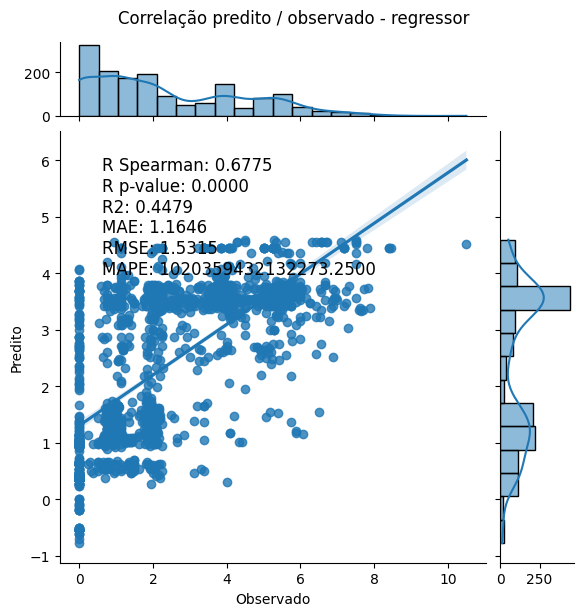

/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 1
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown
19. cat__s

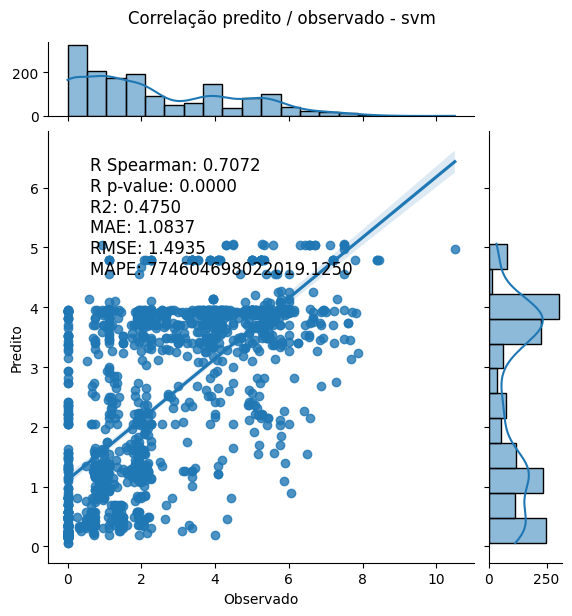

/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unkno

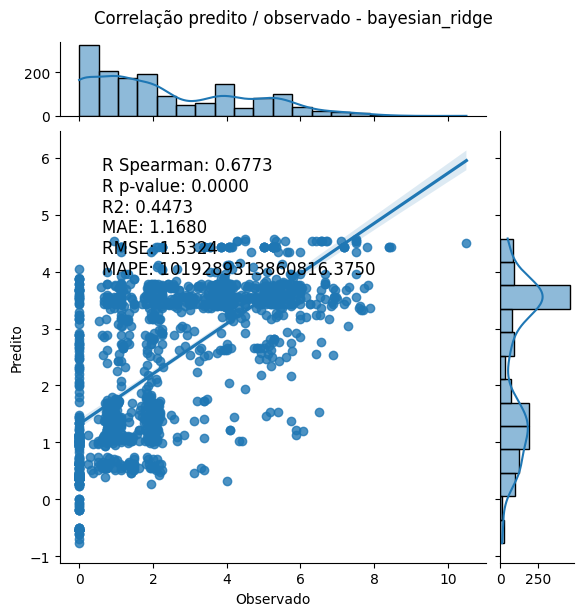

/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Iniciando o Grid Search com Cross Validation...


/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.ap

Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.0001
nn__optimizer -> RMSprop
nn__epochs -> 10
nn__batch_size -> 32
nn__activation2 -> relu
nn__activation1 -> sigmoid
feature_selection__k -> all
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_

/usr/local/lib/python3.10/site-packages/sklearn/pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


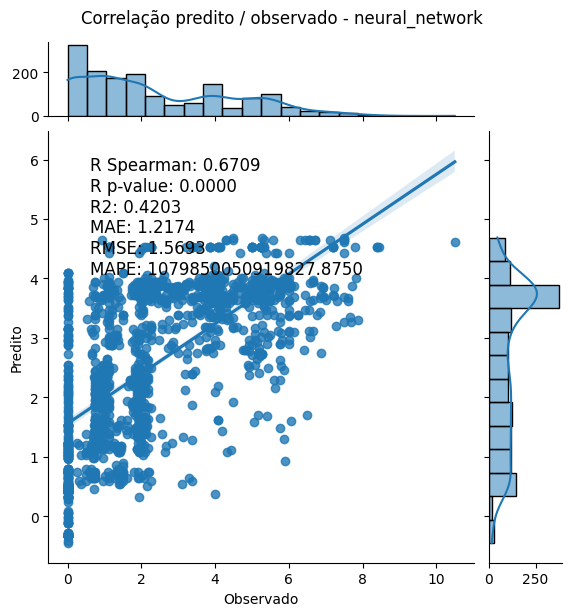

/usr/local/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.10/site-packages/sklearn/pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


In [31]:
from joblib import dump

COLS_REGR = CONTEXTO + ["Date_na", Y]
NOMES_REGR = {"regressor": algoritmo_1, "svm": algoritmo_2,
              "bayesian_ridge": algoritmo_3, "neural_network": algoritmo_4}

regressor_final = Regression(df=tr[COLS_REGR], target=Y)
tr_app, te_app = tr[COLS_REGR].copy(), te[COLS_REGR].copy()

for modelo, nome in NOMES_REGR.items():
    extra = {"n_iter_search": 5} if modelo == "neural_network" else {}
    _, pred_tr = regressor_final.regress(modelo=modelo, **extra)
    tr_app[nome] = np.ravel(pred_tr)
    te_app[nome] = np.ravel(regressor_final.modelos_[modelo].predict(te_app[regressor_final.X.columns]))

In [32]:
dump(tr_app, RAIZ / "app/data/train_resultados_regr")
dump(te_app, RAIZ / "app/data/test_resultados_regr")
print(len(tr_app), len(te_app))
te_app.head()

1558 223


,Species,source_type,Date,Date_na,risco_idx,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
sample,,,,,,,,,
GCA_022210145.1,Klebsiella pneumoniae,Unknown,2018.0,0,5.166667,4.442620,4.797412,4.427937,4.522492
GCA_003183885.1,Escherichia coli,Urinary,2016.0,0,0.000000,1.016741,0.456010,1.015930,1.076429
GCA_014771915.1,Escherichia coli,Gastrointestinal,2000.0,0,0.000000,-0.117269,0.158549,-0.112752,-0.053721
GCA_054478215.1,Escherichia coli,Urinary,2019.0,0,0.000000,1.132722,0.804985,1.132137,1.222959
GCA_015537635.1,Acinetobacter baumannii,Respiratory,2016.0,0,1.500000,1.172347,1.216242,1.217798,1.616311
